In [1]:
#pip install tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D

In [2]:
(x_train, y_train),(x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_teat = x_test.reshape(x_test.shape[0], 28, 28, 1)

In [5]:
input_shape = (28,28,1)

In [6]:
#Convert datatype to float32
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

In [7]:
#Normalize pixel value from (0-255) to (0-1)
x_train /= 255
x_test /= 255

In [8]:
#Create empty Sequential model
model = Sequential()
#Add convolutional layer with 28 filters, 3x3 kernal
model.add(Conv2D(28, (3,3),input_shape=input_shape))
#Add maxpooloing layer
model.add(MaxPooling2D(pool_size=(2,2)))
#Flatten 2D to 1D vector
model.add(Flatten())
#Add fully connected layer with 128 neurons and RelU activation
model.add(Dense(128, activation=tf.nn.relu))
#Add dropout
#model.add(Dropout(0.2))
#Add output layer with 10 neurons
model.add(Dense(10, activation=tf.nn.softmax))


C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
#Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
#Train the model using training images for 10 epochs
model.fit(x=x_train, y=y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.9473 - loss: 0.1775
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9810 - loss: 0.0627
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9887 - loss: 0.0376
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9926 - loss: 0.0242
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9945 - loss: 0.0168
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9952 - loss: 0.0145
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9963 - loss: 0.0105
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9966 - loss: 0.0096
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9969 - loss: 0.0092
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9976 - loss: 0.0068


In [10]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9825 - loss: 0.0931


[0.09311529248952866, 0.9825000166893005]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
6


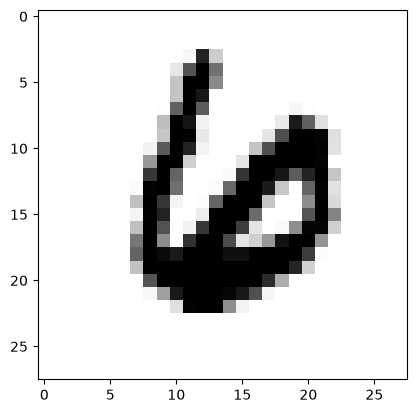

In [12]:
#Import matplotlib
import matplotlib.pyplot as plt
# select any image from dataset
image_index = 6402
#display selected img in greyscale
plt.imshow(x_test[image_index].reshape(28,28), cmap='Greys')
#Reshape into 2D
predict = x_test[image_index].reshape(28,28)
#Predict using trained model
pred = model.predict(x_test[image_index].reshape(1, 28, 28, 1))
#print the digit
print(pred.argmax())